# Week 9, Tuesday

* No homework due this week
* Last homework due Friday of Week 10 (posted soon)
* Final project due during Finals week

## Starting Code

These were our goals.  So far we accomplished the first one.
* Increase the number of predictors from 1 to 4;
* Incorporate a stopping condition;
* Use mini-batches within each epoch, rather than using all training data simultaneously in each epoch.

We'll start with our code from the end of class last week.

In [1]:
from sklearn.datasets import make_regression
from sklearn.linear_model import LinearRegression
import numpy as np

In [2]:
# removed the previous reshape line, since we need 4 columns to go with 4 features
n = 100
x, y, coef = make_regression(n_samples=n, n_features=4, random_state=0, noise=10, bias=-5, coef=True)

In [3]:
# MSE loss function
def L(w,b,x,y):
    error = x@w+b-y
    return (error**2).mean()

In [ ]:
# Define the partial wrt b manually
# important to use mean rahte rthan (1/n) for when we use mini-batches
def Lb(w,b,x,y):
    error = x@w+b-y
    return (2*error).mean()

In [5]:
# Define the partial wrt the four weights manually
def Lw(w,b,x,y):
    error = (x@w+b-y).reshape(-1,1) # reshape to make compatible with x
    return (2*error*x).mean(axis=0)

In [31]:
import warnings

In [38]:
rng = np.random.default_rng(seed = 432)
rng.permutation(100)

array([17, 14,  2, 23, 40, 92, 79, 41, 54, 21, 47, 30, 25,  0, 97, 84, 29,
       88,  5, 20, 74, 58, 95, 22, 38, 51,  3, 59, 67, 87, 10, 13, 56, 89,
       86, 98, 69,  9, 35, 42, 12, 66, 70, 27, 93, 55, 19, 57, 62, 78, 68,
       46, 50, 48,  1,  8, 91, 83, 73, 72, 43, 28, 33, 36, 81, 90, 24,  7,
       26, 94, 71, 37, 11, 32, 75,  4, 99, 76, 82, 63, 64, 31, 60, 34, 44,
       45, 52, 65, 49, 15, 85, 53, 96, 61, 77, 18,  6, 16, 39, 80])

In [41]:
# random starting value
w = np.array([0.1,0.3,-0.2,-0.4])
b = 10

rng = np.random.default_rng(seed = 432)

learn_rate = 0.001
max_epochs = 10000 # repeat update step this many times
tol = 0.0001 # smaller than this number, the more stability we require

# how many of our data points do we use at each update
# each epoch still uses all data points
mini_size = 20

for i in range(max_epochs):
    # beginning or end of for loop for this check have advantages and disadvantages
    if i%10 == 0:
        current_loss = L(w,b,x,y)
        if i == 0:
            previous_loss = current_loss
        elif abs(current_loss - previous_loss) < tol:
            break
        else:
            previous_loss = current_loss
    shuffled_rows = rng.permutation(n)
    for j in range(0, n, mini_size):
        mini_rows = shuffled_rows[j:j+mini_size]
        grad_w = Lw(w, b, x[mini_rows], y[mini_rows])
        grad_b = Lb(w, b, x[mini_rows], y[mini_rows])
        w = w - learn_rate*grad_w
        b = b - learn_rate*grad_b
else:
    warnings.warn(f"Our stopping condition was not met in {max_epochs} epochs")

In [42]:
i

1110

In [17]:
w

array([66.90056734, 86.98831243, 35.19098662, 20.35445417])

In [8]:
b

np.float64(-4.816951645831559)

In [9]:
reg = LinearRegression()

In [10]:
reg.fit(x,y)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](4,)","[66.9 ,86.99,35.19,20.35]"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,-4.817
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,4
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(4)
"singular_ singular_: array of shape (min(X, y),)Singular values of `X`. Only available when `X` is dense.","ndarray[float64](4,)","[11.11,10.37, 9.53, 7.93]"


In [11]:
reg.coef_

array([66.90066686, 86.98832101, 35.19092655, 20.35441935])

In [12]:
reg.intercept_

np.float64(-4.816926917434882)

## PCA with handwritten digits

If we have extra time in today's class, I want to show a demonstration of using PCA with handwritten digits.

In [ ]:
# %pip install seaborn

from sklearn.datasets import load_digits
import matplotlib.pyplot as plt
import seaborn as sns

Note: you may need to restart the kernel to use updated packages.


In [43]:
digits = load_digits()

In [44]:
X = digits.data
y = digits.target

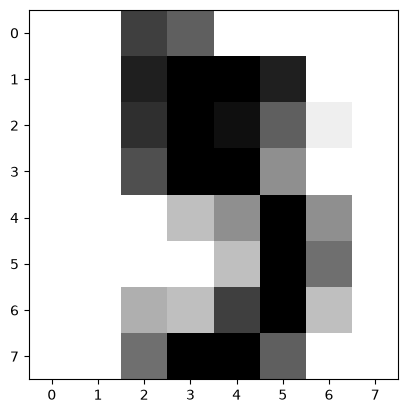

In [45]:
fig, ax = plt.subplots()
ax.imshow(X[5].reshape((8,8)), cmap="binary");

In [46]:
from sklearn.decomposition import PCA

In [47]:
# will reduce from 64 to 2 dimenseions
pca = PCA(n_components = 2)

ook only at the data points corresponding to 0, 2, or 8.

In [51]:
bool_ser = (y == 0) | (y == 2) | (y ==8)

In [52]:
X_sub = X[bool_ser]
y_sub = y[bool_ser]

In [56]:
# first fit, then transofrm, all in one method
X_transform = pca.fit_transform(X_sub)

In [57]:
X_transform.shape

(529, 2)

<Axes: >

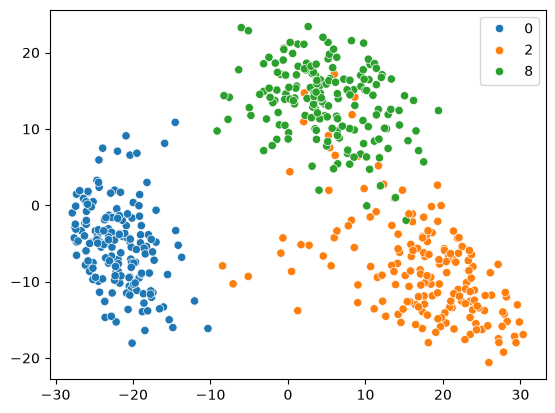

In [60]:
sns.scatterplot(
    x = X_transform[:, 0],
    y = X_transform[:, 1],
    hue = y_sub,
    palette = "tab10"
)